# 01 — EDA et qualité des capteurs (Pump Sensor Data)

Objectifs :
1. Vérifier la régularité de l'index temporel.
2. Identifier les 7 pannes et leurs remises en service.
3. Établir le profil de qualité de chaque capteur : NaN %, variance, % constant, plus longue séquence figée, ADF/KPSS.
4. Lister les capteurs morts et suspects, avec leur justification.
5. Superposer la chronologie des pannes aux signaux.

Toute la logique est dans `src/`. Ce notebook ne fait qu'orchestrer et afficher. Les seuils sont dans `src/config.py`.

Prérequis : `data/raw/sensor.csv` (voir le README).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display

from src.config import PRE_FAILURE_WINDOW, TABLES
from src.data_loading import STATUS_COL, load_pump, pump_sensor_columns
from src.events import events_to_frame, extract_failure_events
from src.quality import classify_sensors, profile_sensors, time_index_report
from src.viz import plot_failure_heatmaps, plot_failure_timeline, plot_quality_overview, save_fig

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 200)

## 1. Chargement et index temporel

In [2]:
df = load_pump()
sensors = pump_sensor_columns(df)
print(f"{df.shape[0]:,} lignes × {len(sensors)} capteurs")
display(time_index_report(df.index).to_frame("valeur"))
display(df[STATUS_COL].value_counts().to_frame("n_points"))

220,320 lignes × 52 capteurs


,valeur
n_points,220320
start,2018-04-01 00:00:00
end,2018-08-31 23:59:00
median_step,0 days 00:01:00
is_monotonic,True
n_duplicates,0
n_gaps,0
largest_gap,0 days 00:00:00
missing_points,0


,n_points
machine_status,
NORMAL,205836
RECOVERING,14477
BROKEN,7


## 2. Pannes

Une panne correspond à une séquence contiguë de `BROKEN`. Son instant `t_f` est le premier point `BROKEN`.

In [3]:
events = extract_failure_events(df[STATUS_COL])
events_table = events_to_frame(events)
events_table.to_csv(TABLES / "pannes.csv")
print(f"{len(events)} pannes détectées")
display(events_table)

7 pannes détectées


,failure_time,recovery_start,recovery_end,downtime,time_since_previous_failure
event_id,,,,,
1,2018-04-12 21:55:00,2018-04-12 21:56:00,2018-04-13 13:39:00,0 days 15:44:00,NaT
2,2018-04-18 00:30:00,2018-04-18 00:31:00,2018-04-20 04:20:00,2 days 03:50:00,5 days 02:35:00
3,2018-05-19 03:18:00,2018-05-19 03:19:00,2018-05-20 01:10:00,0 days 21:52:00,31 days 02:48:00
4,2018-05-25 00:30:00,2018-05-25 00:31:00,2018-05-25 10:35:00,0 days 10:05:00,5 days 21:12:00
5,2018-06-28 22:00:00,2018-06-28 22:01:00,2018-07-04 17:50:00,5 days 19:50:00,34 days 21:30:00
6,2018-07-08 00:11:00,2018-07-08 00:12:00,2018-07-08 00:52:00,0 days 00:41:00,9 days 02:11:00
7,2018-07-25 14:00:00,2018-07-25 14:01:00,2018-07-25 15:15:00,0 days 01:15:00,17 days 13:49:00


## 3. Profil de qualité par capteur

- `nan_pct` : part de valeurs manquantes.
- `mode_pct` : part des mesures égales à la valeur la plus fréquente.
- `zero_step_pct` : % constant, c'est-à-dire la part des pas sans variation. Une valeur élevée indique un capteur figé ou fortement quantifié.
- `longest_frozen` : plus longue séquence de valeurs identiques.
- ADF / KPSS sur la moyenne horaire : `contradictoire` signale en général des ruptures ou des changements de régime (à exploiter en phase 3).

In [4]:
profile = profile_sensors(df, sensors)
classified = classify_sensors(profile)
classified.to_csv(TABLES / "profil_capteurs.csv")

cols = ["status", "nan_pct", "std", "iqr", "mode_pct", "zero_step_pct", "longest_frozen",
        "adf_pvalue", "kpss_pvalue", "stationarity"]
display(classified[cols].round(3))

C:\Users\hp\Desktop\Projet-Capteurs\src\quality.py:76: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  out["adf_pvalue"] = adfuller(x.to_numpy(), autolag="AIC")[1]
C:\Users\hp\Desktop\Projet-Capteurs\src\quality.py:80: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  out["kpss_pvalue"] = kpss(x.to_numpy(), regression="c", nlags="auto")[1]

,status,nan_pct,std,iqr,mode_pct,zero_step_pct,longest_frozen,adf_pvalue,kpss_pvalue,stationarity
sensor,,,,,,,,,,
sensor_00,ok,4.633,0.412,0.061,5.271,12.433,0 days 00:29:00,0.000,0.100,stationnaire
sensor_01,ok,0.167,3.297,3.168,1.206,44.654,0 days 02:15:00,0.000,0.083,stationnaire
sensor_02,ok,0.009,3.667,2.387,1.358,40.917,0 days 01:34:00,0.000,0.100,stationnaire
sensor_03,ok,0.009,2.419,2.474,1.376,69.200,0 days 02:29:00,0.000,0.010,contradictoire (ruptures / régimes probables)
sensor_04,ok,0.009,144.024,10.995,1.116,5.836,0 days 01:17:00,0.000,0.100,stationnaire
sensor_05,suspect,0.009,17.298,10.936,3.648,9.707,4 days 05:09:00,0.000,0.100,stationnaire
sensor_06,ok,2.178,2.164,1.194,2.901,15.193,0 days 00:29:00,0.000,0.010,contradictoire (ruptures / régimes probables)
sensor_07,ok,2.474,2.201,0.521,12.859,25.675,0 days 18:15:00,0.000,0.031,contradictoire (ruptures / régimes probables)
sensor_08,ok,2.318,2.037,0.514,6.594,14.248,0 days 00:29:00,0.000,0.037,contradictoire (ruptures / régimes probables)


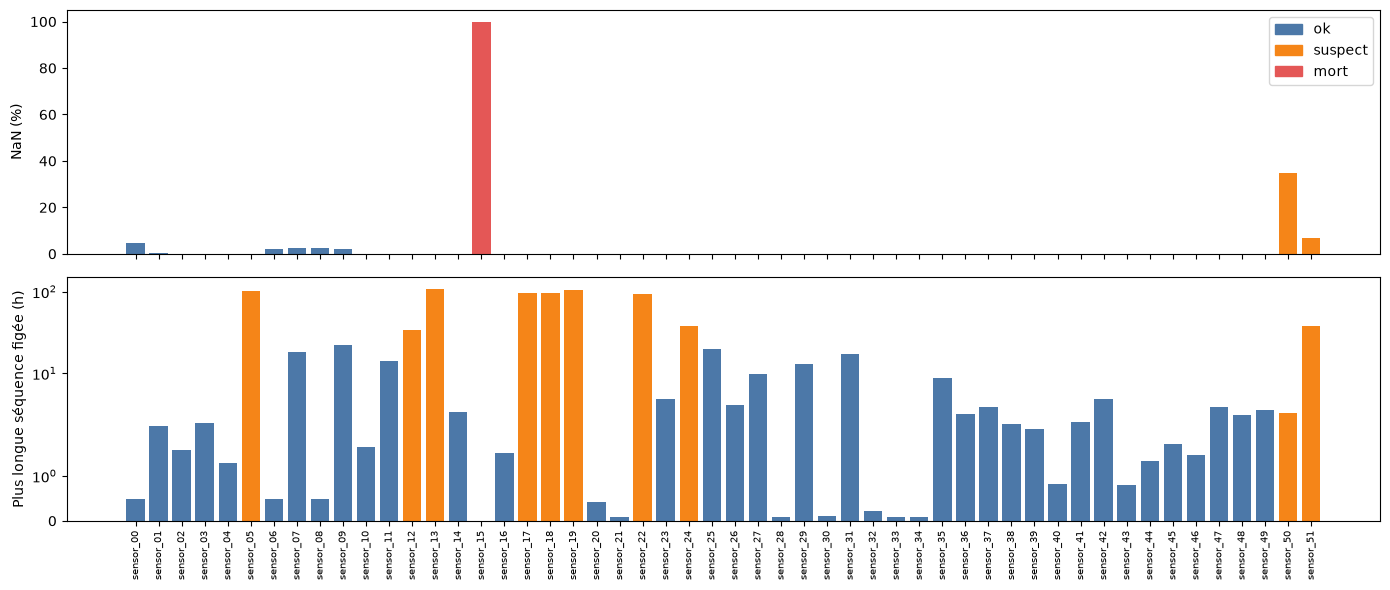

In [5]:
fig = plot_quality_overview(classified)
save_fig(fig, "01_qualite_capteurs");

In [6]:
display(classified["stationarity"].value_counts().to_frame("n_capteurs"))

,n_capteurs
stationarity,
contradictoire (ruptures / régimes probables),39
stationnaire,10
non stationnaire,2
non testable,1


## 4. Capteurs morts et suspects

- **Mort**, exclu de la suite : ≥ 50 % de NaN, variance nulle, ou une seule valeur couvrant ≥ 95 % des mesures.
- **Suspect**, conservé mais traité en phase 2 : ≥ 20 % de NaN, ou figé pendant ≥ 24 h.

In [7]:
flagged = classified.loc[classified["status"] != "ok", ["status", "nan_pct", "mode_pct", "longest_frozen", "justification"]]
flagged.to_csv(TABLES / "capteurs_morts_suspects.csv")
display(flagged.sort_values("status"))

alive = classified.index[classified["status"] != "mort"].tolist()
print(f"{len(alive)} capteurs conservés sur {len(sensors)}")

,status,nan_pct,mode_pct,longest_frozen,justification
sensor,,,,,
sensor_15,mort,100.000000,NaN,0 days 00:00:00,100.0 % de NaN (seuil 50 %)
sensor_05,suspect,0.008624,3.648190,4 days 05:09:00,figé 4 days 05:09:00 à partir du 2018-06-29 09:26
sensor_12,suspect,0.008624,5.926891,1 days 09:54:00,figé 1 days 09:54:00 à partir du 2018-04-18 10:33
sensor_13,suspect,0.008624,6.873323,4 days 11:21:00,figé 4 days 11:21:00 à partir du 2018-06-29 04:09
sensor_17,suspect,0.020879,6.782462,4 days 00:14:00,figé 4 days 00:14:00 à partir du 2018-05-07 05:49
sensor_18,suspect,0.020879,6.819234,4 days 00:14:00,figé 4 days 00:14:00 à partir du 2018-05-07 05:49
sensor_19,suspect,0.007262,7.576803,4 days 07:46:00,figé 4 days 07:46:00 à partir du 2018-05-07 05:59
sensor_22,suspect,0.018609,6.684704,3 days 20:46:00,figé 3 days 20:46:00 à partir du 2018-05-07 05:57
sensor_24,suspect,0.007262,5.211889,1 days 13:35:00,figé 1 days 13:35:00 à partir du 2018-05-09 09:46


51 capteurs conservés sur 52


## 5. Chronologie des pannes superposée aux signaux

- Trait rouge : panne (`t_f`).
- Bande orange : remise en service (`RECOVERING`).
- Bande grise : fenêtre pré-panne du protocole (48 h par défaut).

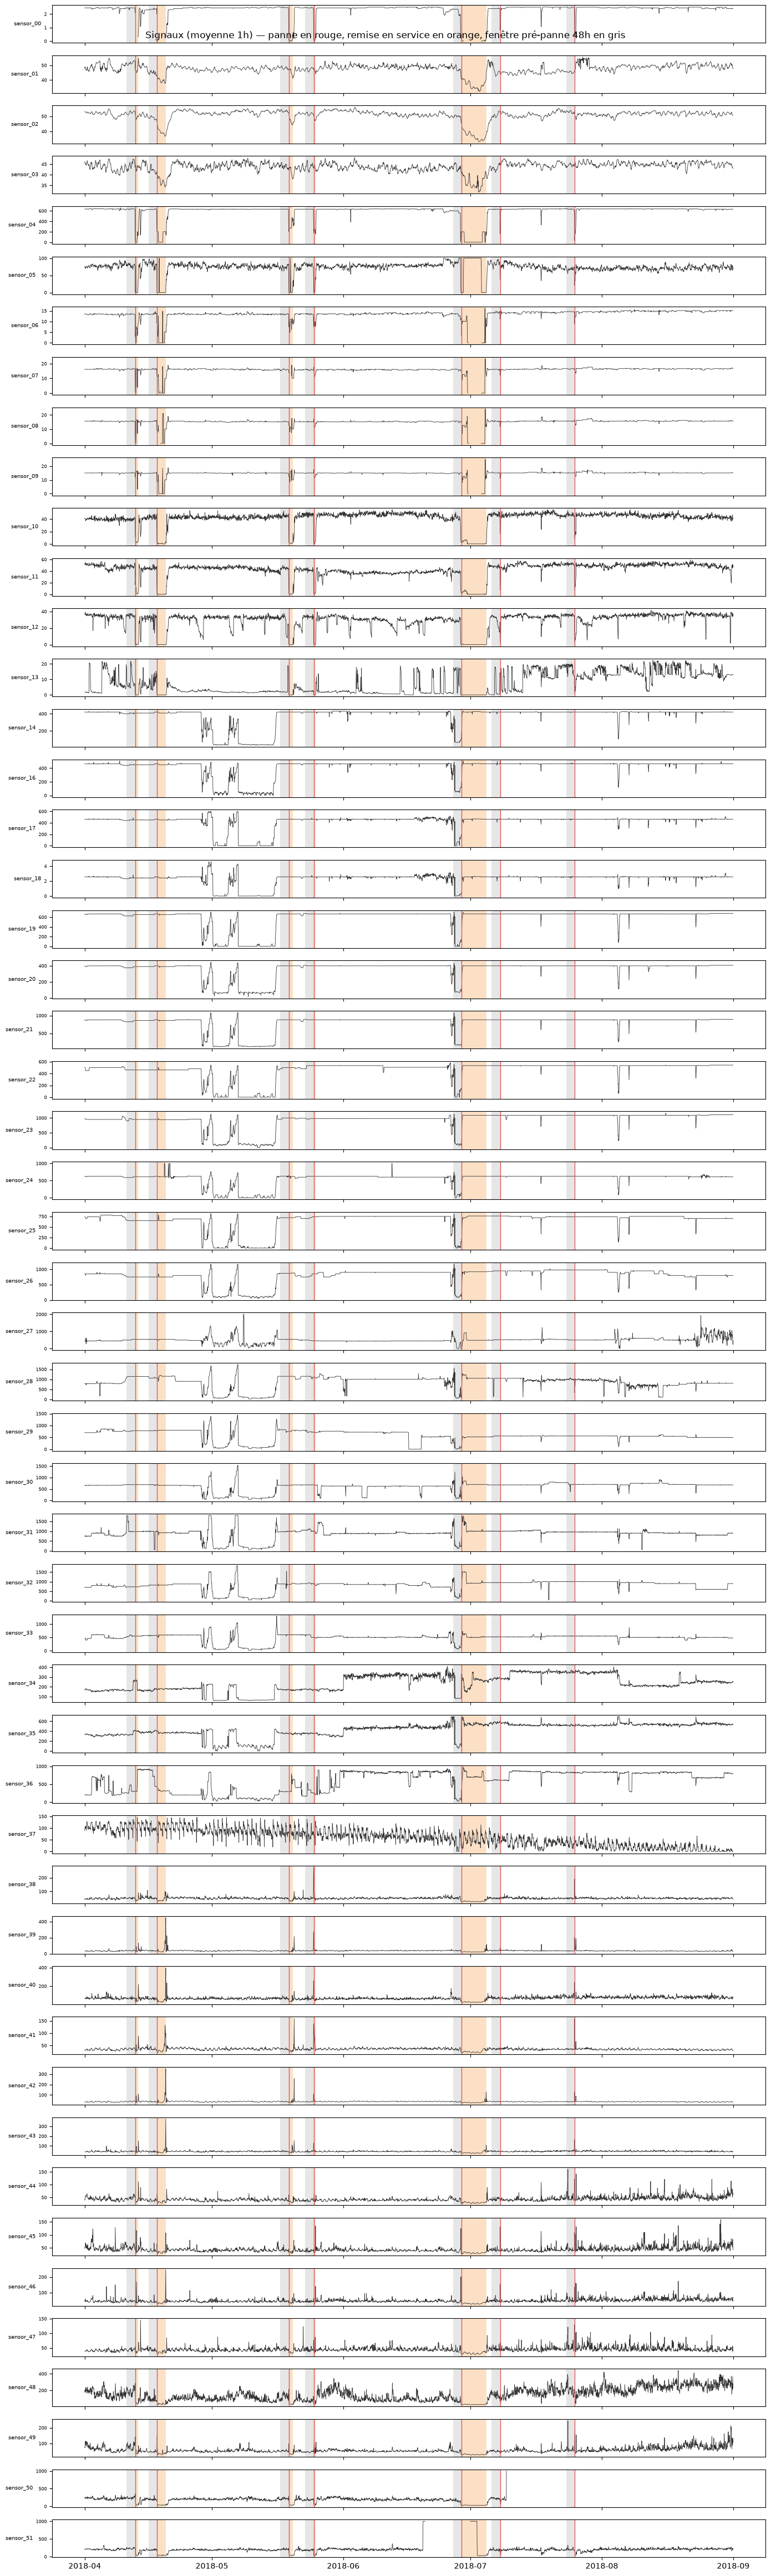

In [8]:
fig = plot_failure_timeline(df, alive, events, resample="1h", window=PRE_FAILURE_WINDOW)
save_fig(fig, "01_chronologie_pannes");

Zoom sur chaque panne, de 72 h avant à 12 h après. Chaque capteur est exprimé en z-score robuste, calculé par rapport à l'ensemble des périodes `NORMAL`. Les bandes rouges ou bleues qui apparaissent **avant** `t_f = 0` désignent les capteurs à suivre en phase 5.

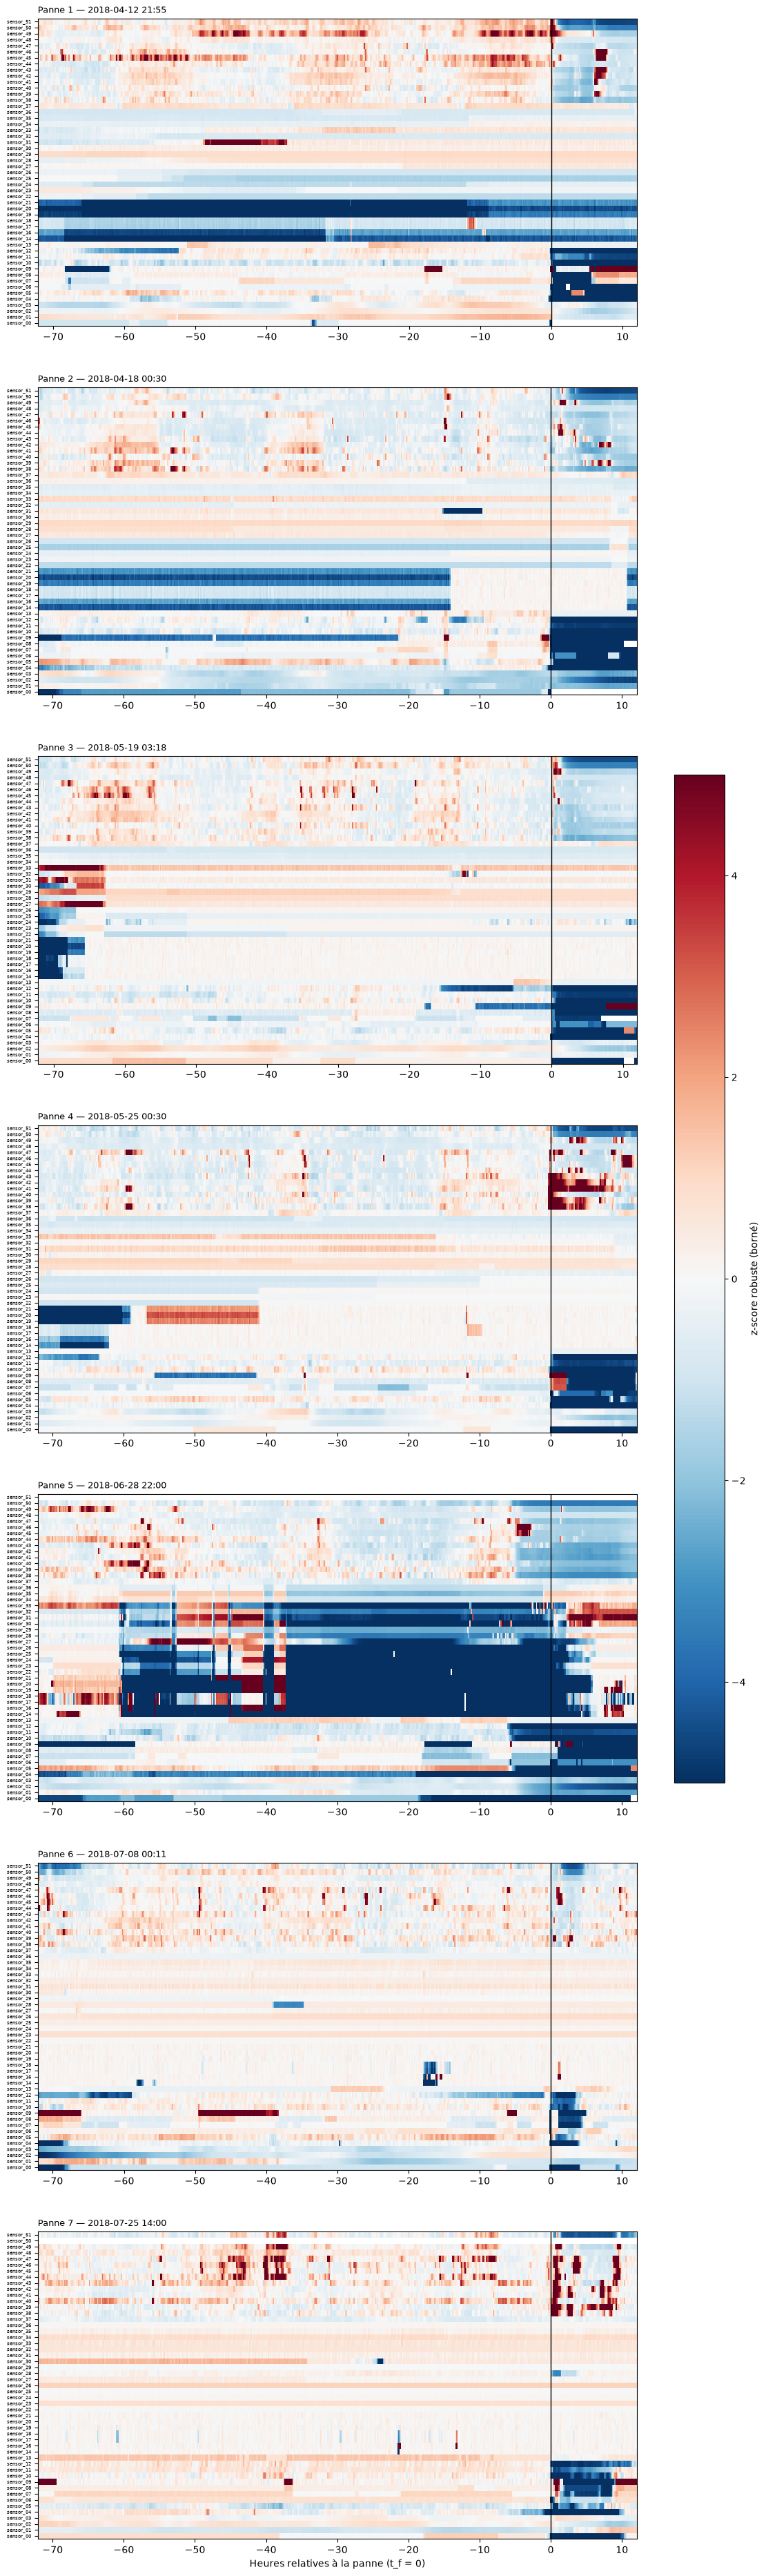

In [9]:
fig = plot_failure_heatmaps(df, alive, events, before="72h", after="12h", resample="10min")
save_fig(fig, "01_zoom_pannes");

## 6. Constats

- **Régularité de l'index** : l'index est monotone, avec un pas médian de 1 minute, sur 220 320 points (du 2018-04-01 00:00 au 2018-08-31 23:59). Aucun trou, aucun doublon, aucun point manquant : l'index ne demande pas de correction.

- **Capteurs morts retenus, et pourquoi** : `sensor_15` est exclu de la suite, car il est vide à 100 % (seuil de mort : 50 % de NaN). Les 51 autres capteurs sont conservés.

- **Capteurs suspects et traitement prévu en phase 2** : dix capteurs sont conservés mais signalés.
  - Figés au moins 24 h : `sensor_05` (4 j 5 h), `sensor_12` (1 j 9 h), `sensor_13` (4 j 11 h), `sensor_17` et `sensor_18` (4 j), `sensor_19` (4 j 7 h), `sensor_22` (3 j 20 h), `sensor_24` (1 j 13 h), `sensor_51` (1 j 14 h).
  - Trop de valeurs manquantes : `sensor_50` (35 % de NaN).
  - Observation : `sensor_17`, `18`, `19` et `22` se figent presque en même temps (2018-05-07, vers 05h50), ce qui suggère une cause commune (acquisition ou maintenance). `sensor_05`, `13` et `51` se figent pendant l'arrêt de la panne 5, et `sensor_12` pendant celui de la panne 2.
  - Traitement envisagé (à décider avec Achraf) : masquer les séquences figées plutôt que les imputer, car une valeur figée n'est pas une vraie mesure ; imputation ou suppression pour `sensor_50`.

- **Remises en service et pannes rapprochées** : les 7 pannes durent de 41 min (panne 6) à environ 5 j 20 h (panne 5) de temps d'arrêt. La plus courte séparation entre une remise en service et la panne suivante est d'environ 3 j 6 h (pannes 5 et 6), soit plus que la fenêtre pré-panne de 48 h. Aucune fenêtre pré-panne n'est donc tronquée.

- **Capteurs qui dérivent visiblement avant les pannes** (lecture visuelle des cartes de chaleur, à confirmer en phase 5) :
  - `sensor_09` s'écarte nettement de la normale avant chacune des pannes.
  - `sensor_12` présente un écart avant 4 pannes sur 7 (pannes 2, 3, 5 et 6), et `sensor_04` avant 4 pannes (2, 3, 5 et 7).
  - `sensor_14`, `16`, `17` et `18` montrent des écarts ponctuels dans plusieurs pannes.
  - La panne 5 est atypique : de nombreux capteurs (`sensor_14` à `sensor_33`) s'écartent fortement pendant environ 37 h avant la panne, puis `sensor_10`, `11`, `12` dans les dernières heures.
  - Les pointes rouges des capteurs `sensor_38` à `sensor_47` apparaissent aussi loin des pannes : ce sont probablement des capteurs bruités, peu discriminants.
  - Ces capteurs sont des candidats, pas des précurseurs confirmés.

- **Capteurs « contradictoires » ADF/KPSS** : 39 capteurs sur 52 sont classés « contradictoires » (ADF rejette la racine unitaire mais KPSS rejette la stationnarité), signe de ruptures ou de changements de régime. Seulement 10 sont stationnaires, 2 non stationnaires et 1 non testable (`sensor_15`). Les contradictoires sont les candidats à la segmentation des régimes (phase 3).